In [1]:
import logging
from pathlib import Path
import numpy as np
import h5py
import matplotlib.pyplot as plt
import jax
from skqd_z2lgt.orchestration.open_output import open_output
from skqd_z2lgt.orchestration.io import load_skqd_result
from skqd_z2lgt.orchestration.common import make_lattice
logging.basicConfig(level=logging.INFO)

In [2]:
string_potential_template = '/data/iiyama/2dz2/string_potential/8x8_{ch0}-{ch1}_pt6.h5'
pkgpath_template = '/mnt/ssh/miyabi_p14000/data/production/full156q-kawasaki-{ch0}-{ch1}-{mu:.1f}'

pt_energies = np.empty((3, 4))
dmrg_energies = np.empty((3, 4))
tsd_energies = np.empty((3, 4))
skqd_energies = np.empty((3, 4))
ch0 = 20
for ich, ch1 in enumerate([21, 22, 23, 24]):
    with h5py.File(string_potential_template.format(ch0=ch0, ch1=ch1)) as source:
        mus = source['mus'][()]
        for imu, mu in enumerate([0.6, 0.8, 1.0]):
            idx = np.argmin(np.abs(mus - mu))
            pt_energies[imu, ich] = source['pt_energies'][idx]
            dmrg_energies[imu, ich] = source['dmrg_energies'][idx]
            tsd_energies[imu, ich] = source['tsd_energies'][idx]

    for imu, mu in enumerate([0.6, 0.8, 1.0]):
        parameters = open_output(pkgpath_template.format(ch0=ch0, ch1=ch1, mu=mu))
        skqd_energies[imu, ich] = np.min(load_skqd_result(parameters, 'cr')[0])

INFO:skqd_z2lgt.orchestration.open_output:Validating configurations in existing file /mnt/ssh/miyabi_p14000/data/production/full156q-kawasaki-20-21-0.6
INFO:skqd_z2lgt.orchestration.open_output:Validating configurations in existing file /mnt/ssh/miyabi_p14000/data/production/full156q-kawasaki-20-21-0.8
INFO:skqd_z2lgt.orchestration.open_output:Validating configurations in existing file /mnt/ssh/miyabi_p14000/data/production/full156q-kawasaki-20-21-1.0
INFO:skqd_z2lgt.orchestration.open_output:Validating configurations in existing file /mnt/ssh/miyabi_p14000/data/production/full156q-kawasaki-20-22-0.6
INFO:skqd_z2lgt.orchestration.open_output:Validating configurations in existing file /mnt/ssh/miyabi_p14000/data/production/full156q-kawasaki-20-22-0.8
INFO:skqd_z2lgt.orchestration.open_output:Validating configurations in existing file /mnt/ssh/miyabi_p14000/data/production/full156q-kawasaki-20-22-1.0
INFO:skqd_z2lgt.orchestration.open_output:Validating configurations in existing file /mn

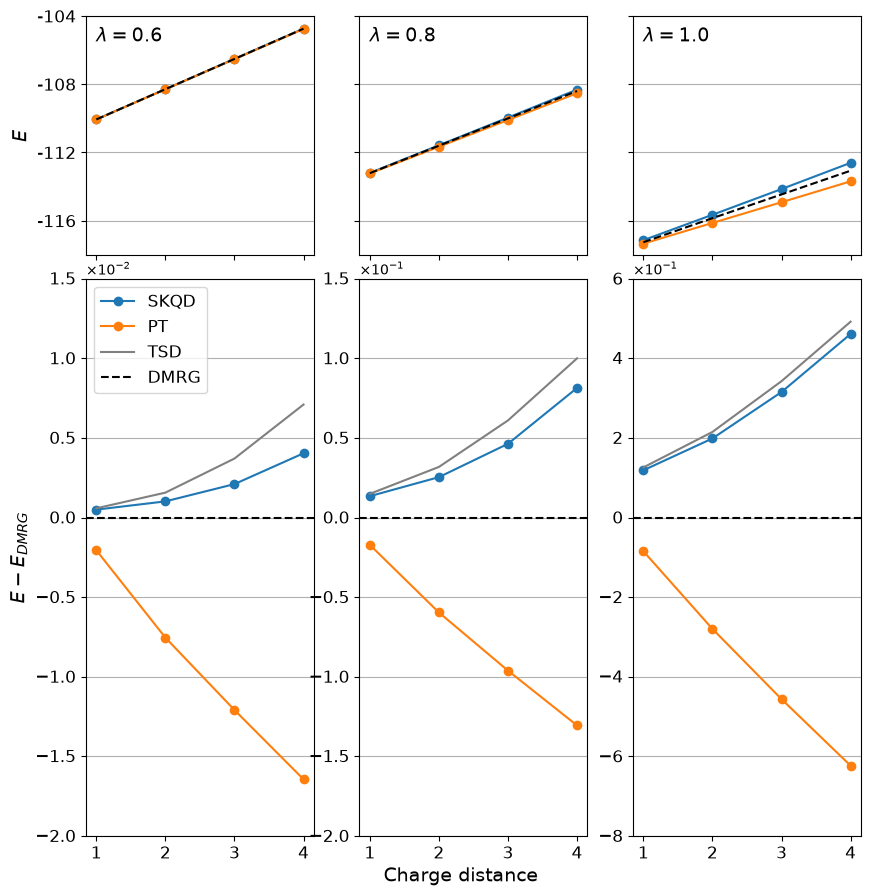

In [39]:
fig, axs = plt.subplots(2, 3, figsize=(10, 10), sharex=True, height_ratios=(0.3, 0.7))
plt.subplots_adjust(hspace=0.06, bottom=0.06)

for imu, mu in enumerate(['0.6', '0.8', '1.0']):
    axs[0, imu].plot(np.arange(1, 5), skqd_energies[imu], marker='o', label='SKQD')
    axs[0, imu].plot(np.arange(1, 5), pt_energies[imu], marker='o', label='PT')
    # axs[0, imu].plot(np.arange(1, 5), tsd_energies[imu], linestyle='-', color='grey', label='TSD')
    axs[0, imu].plot(np.arange(1, 5), dmrg_energies[imu], linestyle='--', color='k', label='DMRG')
    axs[0, imu].text(1., -105.5, fr'$\lambda = {mu}$', fontsize=14)
    
    axs[0, imu].set_ylim(-118., -104.)
    axs[0, imu].grid(axis='y')
    yticks = np.arange(-116, -100, 4)
    if imu == 0:
        axs[0, 0].set_yticks(yticks, [f'{i}' for i in yticks], fontsize=12)
    else:
        axs[0, imu].set_yticks(yticks, [''] * len(yticks))

    axs[1, imu].plot(np.arange(1, 5), skqd_energies[imu] - dmrg_energies[imu], marker='o', label='SKQD')
    axs[1, imu].plot(np.arange(1, 5), pt_energies[imu] - dmrg_energies[imu], marker='o', label='PT')
    axs[1, imu].plot(np.arange(1, 5), tsd_energies[imu] - dmrg_energies[imu], linestyle='-', color='grey', label='TSD')
    axs[1, imu].axhline(0., linestyle='--', color='k', label='DMRG')

    axs[1, imu].set_xticks([1, 2, 3, 4], labels=['1', '2', '3', '4'], fontsize=12)
    axs[1, imu].grid(axis='y')
    axs[1, imu].tick_params(axis='y', labelsize=12)
    axs[1, imu].ticklabel_format(axis='y', style='sci', scilimits=(0, 0), useMathText=True)

axs[0, 0].set_ylabel('$E$', fontsize=14)
axs[1, 0].set_ylim(-0.02, 0.015)
axs[1, 1].set_ylim(-0.20, 0.15)
axs[1, 2].set_ylim(-0.8, 0.6)
axs[1, 0].set_ylabel('$E - E_{DMRG}$', fontsize=14)
axs[1, 0].legend(loc='upper left', fontsize=12)

fig.supxlabel('Charge distance', fontsize=14)
fig.savefig('/data/iiyama/2dz2/plots/rel_string_potential.pdf')
